In [12]:
library(dplyr)
library(tidyr)
library(stringr)
library(ggplot2)
library(ANCOMBC)
library(phyloseq)
library(microbiome)
library(MicrobiomeStat)
library(phyloseq)
library(MicrobiomeStat)

In [2]:
TAXONOMY <- "/beegfs/huangxiaochang/global_oral/taxonomy.tsv"

In [3]:
clean_genus <- function(x) {
  x <- trimws(as.character(x))
  has_genus <- grepl("g__", x)
  extracted <- regmatches(x, regexpr("g__[^;]*", x))
  x[has_genus] <- sub("^g__", "", extracted)
  x <- sub("_.+$", "", x)
  ifelse(is.na(x) | x == "" | x == "g__", NA_character_, x)
}
extract_rank <- function(taxon, prefix) {
  parts <- strsplit(as.character(taxon), ";", fixed = TRUE)[[1]]
  parts <- trimws(parts)
  hit <- parts[startsWith(parts, prefix)]
  if (length(hit) == 0 || hit[1] == prefix) return(NA_character_)
  hit[1]
}
build_family_map <- function() {
  tax <- read.delim(TAXONOMY, stringsAsFactors = FALSE, check.names = FALSE)
  tax_col <- if ("Taxon" %in% colnames(tax)) "Taxon" else colnames(tax)[2]
  fam <- vapply(tax[[tax_col]], extract_rank, character(1), prefix = "f__")
  gen <- vapply(tax[[tax_col]], extract_rank, character(1), prefix = "g__")
  gen_clean <- clean_genus(gen)
  df <- data.frame(Genus = gen_clean, Family = fam, stringsAsFactors = FALSE) %>%
    filter(!is.na(Genus), !is.na(Family), Family != "f__") %>%
    count(Genus, Family, name = "n") %>%
    group_by(Genus) %>%
    arrange(desc(n), Family, .by_group = TRUE) %>%
    slice(1) %>% ungroup()
  setNames(df$Family, df$Genus)
}
family_map <- build_family_map()

In [4]:
# ============================================================================
# 1. Load data
# ============================================================================
cat("=== Loading data ===\n")
genus_data <- read.table("/beegfs/huangxiaochang/global_oral/new_analysis/maaslin3/genus_table_relabund.tsv", header = TRUE, sep = "\t",
                         row.names = 1, check.names = FALSE,
                         comment.char = "", stringsAsFactors = FALSE)
metadata <- read.table("/beegfs/huangxiaochang/global_oral/new_analysis/metadata_oral_qc_dedup.tsv", header = TRUE, sep = "\t",
                       fill = TRUE, comment.char = "", stringsAsFactors = FALSE, quote = "")

# Column mappings
site_map <- c("saliva" = "Saliva", "tongue" = "Tongue", "tooth" = "Tooth",
              "oral swab" = "Oral_swab", "oral mucosa" = "Oral_Mucosa",
              "gingiva" = "Gingiva", "other" = "Others")
metadata$site_cleaned <- ifelse(metadata$site_cleaned %in% names(site_map),
                                site_map[metadata$site_cleaned], metadata$site_cleaned)
metadata$status_cleaned[metadata$status_cleaned %in% c("HC", "Healthy")] <- "Healthy Control"
metadata$age_cleaned_group <- gsub("＞", ">", metadata$age_cleaned_group)

=== Loading data ===


In [5]:
COUNT_SCALE <- 1e5 

In [6]:
# ============================================================================
# 2. Match samples — Saliva only
# ============================================================================
sample_ids <- trimws(as.character(metadata$sample_id))
keep_ids <- !is.na(sample_ids) & sample_ids != "" & !duplicated(sample_ids)
metadata <- metadata[keep_ids, , drop = FALSE]
sample_ids <- sample_ids[keep_ids]

common_samples <- intersect(sample_ids, colnames(genus_data))
cat(sprintf("Common samples overall: %d\n", length(common_samples)))

abund <- genus_data[, common_samples, drop = FALSE]
col_tot <- colSums(abund, na.rm = TRUE)
col_tot[col_tot == 0] <- 1
abund <- round(sweep(abund, 2, col_tot, "/") * COUNT_SCALE)
meta <- metadata[match(common_samples, sample_ids), , drop = FALSE]
rownames(meta) <- common_samples

# Filter to Saliva
needed_cols <- c("age_cleaned_group", "sex_cleaned", "sequencing_region_cleaned",
                 "bioproject_id", "continent_group", "site_cleaned")
for (col in needed_cols) {
  meta[[col]] <- trimws(as.character(meta[[col]]))
  meta[[col]][is.na(meta[[col]]) | meta[[col]] == "" | meta[[col]] == "NA"] <- NA_character_
}

meta <- meta[meta$site_cleaned == "Saliva" & !is.na(meta$site_cleaned), , drop = FALSE]
abund <- abund[, rownames(meta), drop = FALSE]
cat(sprintf("Saliva samples before complete-case filter: %d\n", nrow(meta)))

valid <- complete.cases(meta[, needed_cols]) & meta$age_cleaned_group != "NA" & meta$sex_cleaned != "NA" &
  meta$age_cleaned_group != "" & meta$sex_cleaned != "" &
  meta$sequencing_region_cleaned != "" & meta$bioproject_id != ""
meta <- meta[valid, , drop = FALSE]
abund <- abund[, rownames(meta), drop = FALSE]
cat(sprintf("Saliva samples with complete metadata: %d\n", nrow(meta)))

# Factorize
meta$age_cleaned_group <- factor(meta$age_cleaned_group)
meta$sex_cleaned <- factor(meta$sex_cleaned)
meta$sequencing_region_cleaned <- factor(meta$sequencing_region_cleaned)
meta$continent_group <- factor(meta$continent_group)
meta$bioproject_id <- factor(meta$bioproject_id)

# Reference levels
if ("18-60 years" %in% levels(meta$age_cleaned_group))
  meta$age_cleaned_group <- relevel(meta$age_cleaned_group, ref = "18-60 years")
if ("F" %in% levels(meta$sex_cleaned))
  meta$sex_cleaned <- relevel(meta$sex_cleaned, ref = "F")
if ("V4" %in% levels(meta$sequencing_region_cleaned))
  meta$sequencing_region_cleaned <- relevel(meta$sequencing_region_cleaned, ref = "V4")

cat(sprintf("Age levels (%d): %s\n", nlevels(meta$age_cleaned_group),
            paste(levels(meta$age_cleaned_group), collapse=", ")))
cat(sprintf("Sex levels (%d): %s\n", nlevels(meta$sex_cleaned),
            paste(levels(meta$sex_cleaned), collapse=", ")))
cat(sprintf("Region levels (%d): %s\n", nlevels(meta$sequencing_region_cleaned),
            paste(levels(meta$sequencing_region_cleaned), collapse=", ")))
cat(sprintf("BioProject levels: %d\n", nlevels(meta$bioproject_id)))

Common samples overall: 42424
Saliva samples before complete-case filter: 27085
Saliva samples with complete metadata: 14120
Age levels (6): 18-60 years, 0-6 months, 12-18 years, 3-12 years, 6-36 months, <ef><bc><9e>60 years
Sex levels (2): F, M
Region levels (8): V4, V1, V1-V2, V1-V3, V3, V3-V4, V4-V5, V6-V8
BioProject levels: 85


In [7]:
sub <- abund
sub <- sub[rowSums(sub) > 0, , drop = FALSE]
sub <- sub[rowSums(sub > 0) >= 2, , drop = FALSE]

# ANCOM-BC2

In [8]:
REF_AGE <- "18-60 years"
# ============================================================================
# 3. Run ANCOM-BC2
# ============================================================================
library(phyloseq)

cat("\n=== Running ANCOM-BC2 for Saliva age analysis ===\n")

stopifnot(identical(colnames(sub), rownames(meta)))

meta_use <- meta %>%
  mutate(
    age_cleaned_group = factor(
      age_cleaned_group,
      levels = c(REF_AGE, setdiff(sort(unique(as.character(age_cleaned_group))), REF_AGE))
    ),
    sex_cleaned               = factor(sex_cleaned),
    sequencing_region_cleaned = factor(sequencing_region_cleaned),
    continent_group           = factor(continent_group),
    bioproject_id             = factor(bioproject_id)
  )
ps <- phyloseq(
  otu_table(as.matrix(round(sub)), taxa_are_rows = TRUE),
  sample_data(meta_use)
)
out <- ancombc2(
    data         = ps,         
    tax_level    = NULL,
    fix_formula  = "age_cleaned_group + sex_cleaned + sequencing_region_cleaned + continent_group",
    rand_formula = "(1 | bioproject_id)",
    p_adj_method = "BH",
    prv_cut      = 0.10,
    lib_cut      = 0,
    s0_perc      = 0.05,
    group        = "age_cleaned_group",
    struc_zero   = TRUE,
    neg_lb       = FALSE,
    alpha        = 0.1,
    verbose      = TRUE,
    global       = TRUE,
    pairwise     = FALSE,
    dunnet       = FALSE,
    trend        = FALSE,
    iter_control  = list(tol = 1e-5, max_iter = 20, verbose = FALSE),
    em_control    = list(tol = 1e-5, max_iter = 100),
    lme_control   = lme4::lmerControl(),
    mdfdr_control = list(fwer_ctrl_method = "BH", B = 100)
)


=== Running ANCOM-BC2 for Saliva age analysis ===


Checking the input data type ...

The input data is of type: phyloseq

PASS

Checking the sample metadata ...

The specified variables in the formula: age_cleaned_group, sex_cleaned, sequencing_region_cleaned, continent_group

The available variables in the sample metadata: bioproject_id, sample_id, subject_id, chim_perc, asv_count, total_reads, sample_cr_mapping_rate, study_cr_mapping_rate, Observed, Shannon, Simpson, InvSimpson, Chao1, age, age_info, bmi, sex, platform, sequencing_region, pcr_primers, country, site, site_group, disease_study, status, title, public_time, matched_samples, is_time_series, age_cleaned, bmi_cleaned, age_cleaned_group, age_info_cleaned, bmi_cleaned_group, sex_cleaned, platform_cleaned, sequencing_region_cleaned, country_cleaned, continent_group, site_cleaned, site_group_cleaned, disease_study_cleaned, status_cleaned, asv_le_30, study_asv_lt30_high, chim_gt_25, study_chim_gt25_high, sample_cr_mapping_low, study_cr_mapping_low

PASS

Checking other arguments

In [9]:
# ============================================================================
# 4. Extract age results 
# ============================================================================
Q_THRESHOLD <- 0.05
res_wide <- out$res
# write.table(res_wide, file.path("all_results_age_saliva_ANCOM_BC2.tsv"), sep = "\t", quote = TRUE, row.names = FALSE)
n_tax    <- nrow(res_wide)

lfc_cols <- grep("^lfc_age_cleaned_group", names(res_wide), value = TRUE)
lvls     <- sub("^lfc_age_cleaned_group", "", lfc_cols)

get_col <- function(prefix, lvl, type = c("numeric", "logical")) {
  type <- match.arg(type)
  cn   <- paste0(prefix, "age_cleaned_group", lvl)
  if (cn %in% names(res_wide)) {
    v <- res_wide[[cn]]
    if (type == "numeric") as.numeric(v) else as.logical(v)
  } else {
    if (type == "numeric") rep(NA_real_, n_tax) else rep(NA, n_tax)
  }
}

age_results <- bind_rows(lapply(lvls, function(lvl) {
  data.frame(
    feature         = as.character(res_wide$taxon),
    metadata        = "age_cleaned_group",
    value           = lvl,
    coef            = get_col("lfc_",       lvl, "numeric"),
    stderr          = get_col("se_",        lvl, "numeric"),
    W               = get_col("W_",         lvl, "numeric"),
    pval            = get_col("p_",         lvl, "numeric"),
    qval_individual = get_col("q_",         lvl, "numeric"),
    diff_abn        = get_col("diff_",      lvl, "logical"),
    passed_ss       = get_col("passed_ss_", lvl, "logical"),
    stringsAsFactors = FALSE
  )
})) %>%
  mutate(
    coef            = as.numeric(unlist(coef)),
    stderr          = as.numeric(unlist(stderr)),
    W               = as.numeric(unlist(W)),
    pval            = as.numeric(unlist(pval)),
    qval_individual = as.numeric(unlist(qval_individual)),
    diff_abn        = as.logical(unlist(diff_abn)),
    passed_ss       = as.logical(unlist(passed_ss)),
    Genus           = clean_genus(feature)
  ) %>%
  filter(!is.na(Genus)) %>%
  arrange(qval_individual, desc(abs(coef)))

age_sig <- age_results %>%
  filter(!is.na(qval_individual), qval_individual < Q_THRESHOLD,
         is.na(passed_ss) | passed_ss)

cat(sprintf("\nTotal age associations: %d\n", nrow(age_results)))
cat(sprintf("Significant (q<%.2f): %d (%d unique genera)\n",
            Q_THRESHOLD, nrow(age_sig), n_distinct(age_sig$Genus)))


Total age associations: 375
Significant (q<0.05): 52 (28 unique genera)


In [19]:
# ============================================================================
# 5. Age heatmap
# ============================================================================
if (nrow(age_sig) > 0) {
  hm_data <- age_sig %>%
    mutate(
      sig_label   = ifelse(coef > 0, "+", "-"),
      q_plot      = ifelse(qval_individual <= 0, 1e-300, qval_individual),
      signed_logq = pmin(-log10(q_plot), 10) * sign(coef)
    )

  genus_order <- hm_data %>%
    group_by(Genus) %>%
    summarise(min_q = min(qval_individual), .groups = "drop") %>%
    arrange(min_q) %>% pull(Genus)

  age_values <- c("0-6 months", "6-36 months", "3-12 years", "12-18 years", "18-60 years", ">60 years", "＞60 years")
  present_values <- setdiff(unique(hm_data$value), NA)
  age_values <- c(age_values[age_values %in% present_values],
                  setdiff(present_values, age_values))
  hm_data <- hm_data %>%
    mutate(
      Genus = factor(Genus, levels = rev(genus_order)),
      value = factor(value, levels = age_values)
    )

  axis_labels <- sapply(genus_order, function(g) {
    fam <- family_map[g]; if (is.na(fam)) fam <- "f__"
    paste0(str_pad(fam, width = max(nchar(family_map), na.rm = TRUE) + 2, side = "right"),
           "g__", g)
  })
  names(axis_labels) <- genus_order

  w <- max(8, length(age_values) * 1.2)
  h <- max(6, length(genus_order) * 0.25)

  p <- ggplot(hm_data, aes(x = value, y = Genus, fill = signed_logq)) +
    geom_tile(color = "grey85", linewidth = 0.15) +
    geom_text(aes(label = sig_label), size = 3, fontface = "bold") +
    scale_fill_gradient2(low = "#2166AC", mid = "#F7F7F7", high = "#D73027",
                         midpoint = 0, limits = c(-10, 10), name = "signed\n-log10(q)") +
    scale_y_discrete(labels = axis_labels) +
    labs(title = "Saliva Age-Associated Microbiota (ANCOM-BC2)",
         subtitle = paste0("Ref: ", REF_AGE, "; q < ", Q_THRESHOLD,
                           "; +/- indicates LFC direction vs reference"),
         x = "Age Group", y = NULL) +
    theme_minimal(base_size = 11) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1, size = 9),
          axis.text.y = element_text(size = 7, family = "mono"),
          panel.grid = element_blank(),
          legend.position = "bottom",
          plot.title = element_text(hjust = 0.5, face = "bold"))

  # ggsave(file.path(OUT_DIR, "age_heatmap_ancombc2.pdf"), p,
  #        width = w, height = h, limitsize = FALSE)

  cat(sprintf("Saved age heatmap: %d genera x %d age levels (%.1f x %.1f in)\n",
              length(genus_order), length(age_values), w, h))
}

cat("=== Age saliva analysis (ANCOM-BC2) done ===\n")

Saved age heatmap: 79 genera x 5 age levels (8.0 x 19.8 in)
=== Age saliva analysis (ANCOM-BC2) done ===


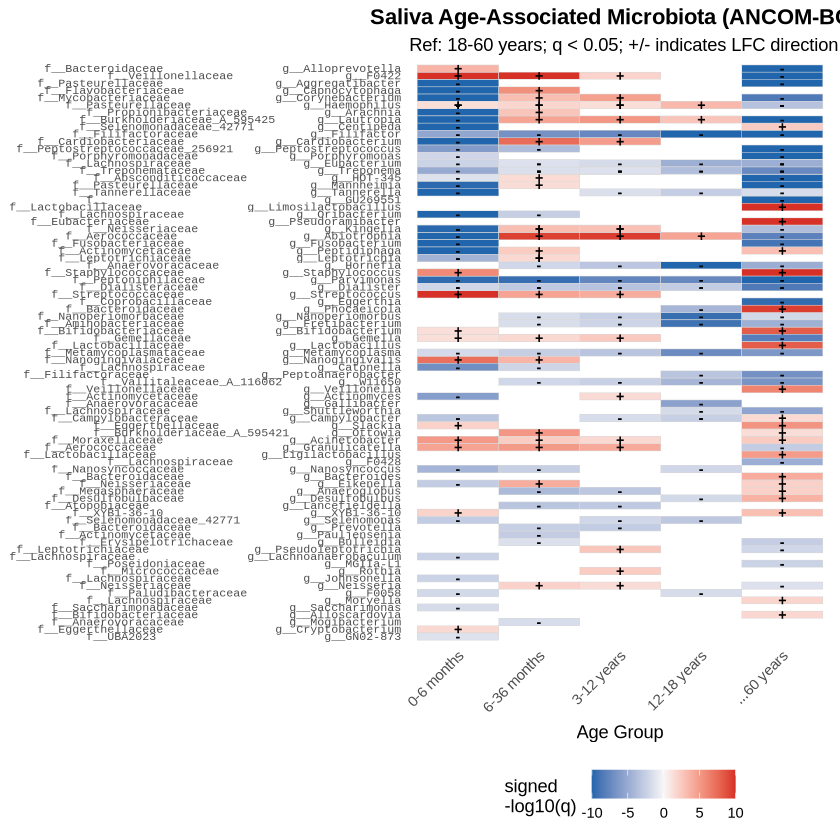

In [20]:
p

# LinDA

In [15]:
# ============================================================================
# 3. Run MaAsLin3
# ============================================================================
REF_AGE <- "18-60 years"
Q_THRESHOLD <- 0.05
# ============================================================================
# 3. Run LinDA
# ============================================================================
cat("\n=== Running LinDA for Saliva age analysis ===\n")
stopifnot(identical(colnames(sub), rownames(meta)))

meta_use <- meta %>%
  mutate(
    age_cleaned_group = factor(
      age_cleaned_group,
      levels = c(REF_AGE, setdiff(sort(unique(as.character(age_cleaned_group))), REF_AGE))
    ),
    sex_cleaned               = factor(sex_cleaned),
    sequencing_region_cleaned = factor(sequencing_region_cleaned),
    continent_group           = factor(continent_group),
    bioproject_id             = factor(bioproject_id)
  )

linda_obj <- linda(
  feature.dat       = as.matrix(round(sub)),   
  meta.dat          = meta_use,
  formula           = "~ age_cleaned_group + sex_cleaned + sequencing_region_cleaned + continent_group + (1 | bioproject_id)",
  feature.dat.type  = "count",
  prev.filter       = 0.10,        
  mean.abund.filter = 0,           
  is.winsor         = TRUE,        
  outlier.pct       = 0.03,
  adaptive          = TRUE,         
  zero.handling     = "pseudo-count",
  pseudo.cnt        = 0.5,
  p.adj.method      = "BH",
  alpha             = Q_THRESHOLD)


=== Running LinDA for Saliva age analysis ===
279  features are filtered!
The filtered data has  14120  samples and  95  features will be tested!
Imputation approach is used.
Fit linear mixed effects models ...
Completed.


In [16]:
# ============================================================================
# 4. Extract age results
# ============================================================================
# linda_obj$output 是一个命名 list,名字 = 模型里各非参考水平的项
# 年龄相关项形如 "age_cleaned_group0-6 months"
out_list  <- linda_obj$output
age_terms <- grep("^age_cleaned_group", names(out_list), value = TRUE)

age_results <- bind_rows(lapply(age_terms, function(term) {
  df  <- out_list[[term]]
  lvl <- sub("^age_cleaned_group", "", term)
  data.frame(
    feature         = rownames(df),
    metadata        = "age_cleaned_group",
    value           = lvl,
    coef            = as.numeric(df$log2FoldChange),  # log2 尺度
    stderr          = as.numeric(df$lfcSE),
    W               = as.numeric(df$stat),
    pval            = as.numeric(df$pvalue),
    qval_individual = as.numeric(df$padj),
    diff_abn        = as.logical(df$reject),
    stringsAsFactors = FALSE
  )
})) %>%
  mutate(Genus = clean_genus(feature)) %>%
  filter(!is.na(Genus)) %>%
  arrange(qval_individual, desc(abs(coef)))

# write.table(age_results, "age_results_saliva_LinDA.tsv",
#             sep = "\t", quote = TRUE, row.names = FALSE)

# LinDA 无敏感性分析,只按 q 阈值筛
age_sig <- age_results %>%
  filter(!is.na(qval_individual), qval_individual < Q_THRESHOLD)

cat(sprintf("\nTotal age associations: %d\n", nrow(age_results)))
cat(sprintf("Significant (q<%.2f): %d (%d unique genera)\n",
            Q_THRESHOLD, nrow(age_sig), n_distinct(age_sig$Genus)))


Total age associations: 475
Significant (q<0.05): 231 (79 unique genera)


In [21]:
# ============================================================================
# 5. Age heatmap
# ============================================================================
if (nrow(age_sig) > 0) {
  hm_data <- age_sig %>%
    mutate(
      sig_label   = ifelse(coef > 0, "+", "-"),
      q_plot      = ifelse(qval_individual <= 0, 1e-300, qval_individual),
      signed_logq = pmin(-log10(q_plot), 10) * sign(coef)
    )

  genus_order <- hm_data %>%
    group_by(Genus) %>%
    summarise(min_q = min(qval_individual), .groups = "drop") %>%
    arrange(min_q) %>% pull(Genus)

  age_values <- c("0-6 months", "6-36 months", "3-12 years", "12-18 years", "18-60 years", ">60 years", "＞60 years")
  present_values <- setdiff(unique(hm_data$value), NA)
  age_values <- c(age_values[age_values %in% present_values],
                  setdiff(present_values, age_values))
  hm_data <- hm_data %>%
    mutate(
      Genus = factor(Genus, levels = rev(genus_order)),
      value = factor(value, levels = age_values)
    )

  axis_labels <- sapply(genus_order, function(g) {
    fam <- family_map[g]; if (is.na(fam)) fam <- "f__"
    paste0(str_pad(fam, width = max(nchar(family_map), na.rm = TRUE) + 2, side = "right"),
           "g__", g)
  })
  names(axis_labels) <- genus_order

  w <- max(8, length(age_values) * 1.2)
  h <- max(6, length(genus_order) * 0.25)

  p <- ggplot(hm_data, aes(x = value, y = Genus, fill = signed_logq)) +
    geom_tile(color = "grey85", linewidth = 0.15) +
    geom_text(aes(label = sig_label), size = 3, fontface = "bold") +
    scale_fill_gradient2(low = "#2166AC", mid = "#F7F7F7", high = "#D73027",
                         midpoint = 0, limits = c(-10, 10), name = "signed\n-log10(q)") +
    scale_y_discrete(labels = axis_labels) +
    labs(title = "Saliva Age-Associated Microbiota (LinDA)",
         subtitle = paste0("Ref: ", REF_AGE, "; q < ", Q_THRESHOLD,
                           "; +/- indicates log2FC direction vs reference"),
         x = "Age Group", y = NULL) +
    theme_minimal(base_size = 11) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1, size = 9),
          axis.text.y = element_text(size = 7, family = "mono"),
          panel.grid = element_blank(),
          legend.position = "bottom",
          plot.title = element_text(hjust = 0.5, face = "bold"))

  # ggsave(file.path(OUT_DIR, "age_heatmap_linda.pdf"), p,
  #        width = w, height = h, limitsize = FALSE)

  cat(sprintf("Saved age heatmap: %d genera x %d age levels (%.1f x %.1f in)\n",
              length(genus_order), length(age_values), w, h))
}

cat("=== Age saliva analysis (LinDA) done ===\n")

Saved age heatmap: 79 genera x 5 age levels (8.0 x 19.8 in)
=== Age saliva analysis (LinDA) done ===


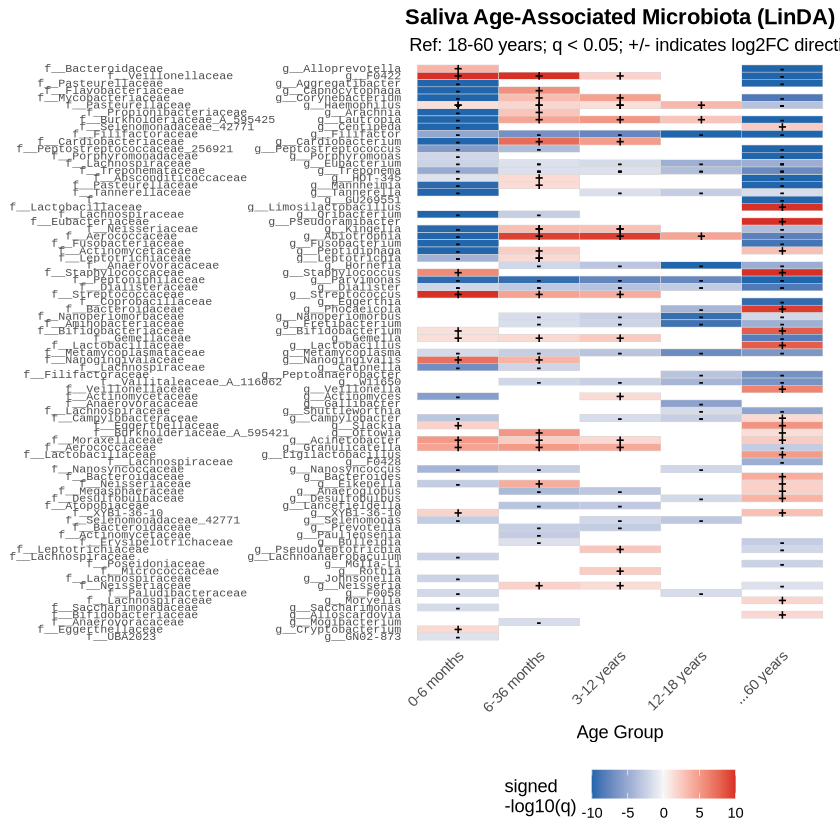

In [22]:
p